In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Data
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

# 2. Quick Clean
df['Date'] = pd.to_datetime(df['Date'])
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm', 'RISK_MM'], errors='ignore')
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# Fill missing values
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=['object']).columns:
    if col != 'RainTomorrow':
        df[col] = df[col].fillna(df[col].mode()[0])

# Convert Wind Directions
compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))
for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_sin'] = np.sin(np.radians(df[col].map(direction_map)))
        df[col + '_cos'] = np.cos(np.radians(df[col].map(direction_map)))
        df = df.drop(columns=[col])

df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)

# Split by Time
train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

# Features for MaxTemp (Morning features only)
features = [col for col in df_clean.columns if col not in ['MaxTemp', 'Temp3pm', 'RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['MaxTemp']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

print(f"Data ready. Train: {X_train.shape}, Test: {X_test.shape}")

Data ready. Train: (98988, 65), Test: (43205, 65)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load Data
file_path = '/content/drive/MyDrive/CSC4110_G07/data/weatherAUS.csv'
df = pd.read_csv(file_path)

# 2. Quick Clean
df['Date'] = pd.to_datetime(df['Date'])
df['Month'] = df['Date'].dt.month  # <--- THIS IS THE FIX (Creates the Month column)
df = df.dropna(subset=['RainTomorrow'])
df = df.drop(columns=['Evaporation', 'Sunshine', 'Cloud9am', 'Cloud3pm', 'RISK_MM'], errors='ignore')
df['RainToday'] = df['RainToday'].map({'No': 0, 'Yes': 1})
df['RainTomorrow'] = df['RainTomorrow'].map({'No': 0, 'Yes': 1})

# Fill missing values
for col in df.select_dtypes(include=['float64', 'int64']).columns:
    df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=['object']).columns:
    if col != 'RainTomorrow':
        df[col] = df[col].fillna(df[col].mode()[0])

# Convert Wind Directions
compass_points = ['N', 'NNE', 'NE', 'ENE', 'E', 'ESE', 'SE', 'SSE', 'S', 'SSW', 'SW', 'WSW', 'W', 'WNW', 'NW', 'NNW']
angles = np.arange(0, 360, 22.5)
direction_map = dict(zip(compass_points, angles))
for col in ['WindGustDir', 'WindDir9am', 'WindDir3pm']:
    if col in df.columns:
        df[col + '_sin'] = np.sin(np.radians(df[col].map(direction_map)))
        df[col + '_cos'] = np.cos(np.radians(df[col].map(direction_map)))
        df = df.drop(columns=[col])

df_clean = pd.get_dummies(df, columns=['Location'], drop_first=True)

# Split by Time
train_mask = df_clean['Date'] < '2015-01-01'
test_mask = df_clean['Date'] >= '2015-01-01'

# Features for MaxTemp (Morning features only)
features = [col for col in df_clean.columns if col not in ['MaxTemp', 'Temp3pm', 'RainTomorrow', 'Date']]
X = df_clean[features]
y = df_clean['MaxTemp']

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

print(f"Data ready. Train: {X_train.shape}, Test: {X_test.shape}")
print("Month column exists in X_train:", 'Month' in X_train.columns)

Data ready. Train: (98988, 66), Test: (43205, 66)
Month column exists in X_train: True


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


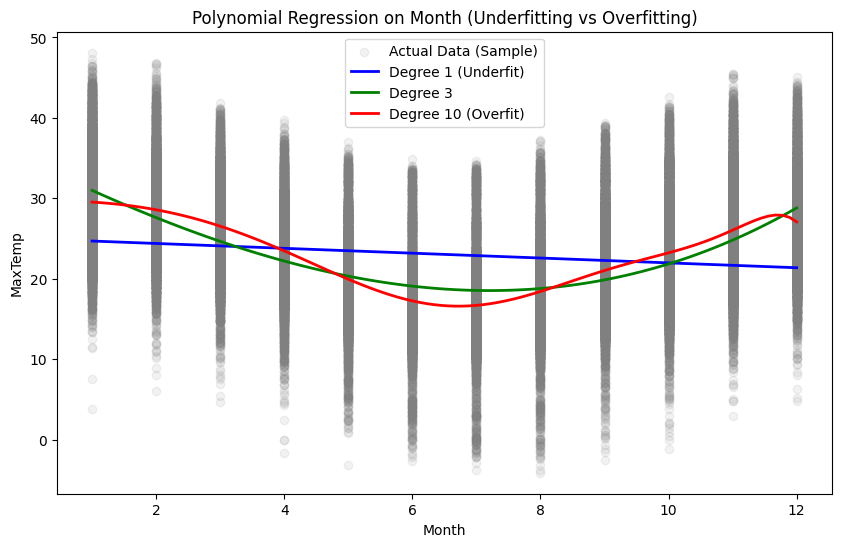

In [6]:
# Exam Skill: Plot degree 1, 3, and 10 curves of month
month_train = X_train[['Month']]
y_train_plot = y_train

plt.figure(figsize=(10, 6))
plt.scatter(month_train, y_train_plot, alpha=0.1, color='gray', label='Actual Data (Sample)')

degrees = [1, 3, 10]
colors = ['blue', 'green', 'red']
month_range = np.linspace(1, 12, 100).reshape(-1, 1)

for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(month_train)

    lr = LinearRegression()
    lr.fit(X_poly, y_train_plot)

    # Predict on the smooth range of months
    month_range_poly = poly.transform(month_range)
    y_range_pred = lr.predict(month_range_poly)

    label = f"Degree {degree}"
    if degree == 1: label += " (Underfit)"
    if degree == 10: label += " (Overfit)"

    plt.plot(month_range, y_range_pred, color=color, linewidth=2, label=label)

plt.title('Polynomial Regression on Month (Underfitting vs Overfitting)')
plt.xlabel('Month')
plt.ylabel('MaxTemp')
plt.legend()
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/under_over_fit.png')
plt.show()

In [7]:
ridge_results = {}
lasso_results = {}
alphas = [0.01, 0.1, 1, 10]

# Scale the full feature set for Ridge/Lasso
scaler_reg = StandardScaler()
X_train_scaled = scaler_reg.fit_transform(X_train)
X_test_scaled = scaler_reg.transform(X_test)

for alpha in alphas:
    # Ridge
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge.fit(X_train_scaled, y_train)
    ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled)))
    ridge_results[alpha] = ridge_rmse

    # Lasso
    lasso = Lasso(alpha=alpha, random_state=42, max_iter=5000)
    lasso.fit(X_train_scaled, y_train)
    lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso.predict(X_test_scaled)))

    # Count zero coefficients for Lasso
    zero_coefs = np.sum(lasso.coef_ == 0)
    lasso_results[alpha] = {'Test RMSE': lasso_rmse, 'Zero Coefs': zero_coefs}

print("Ridge Results (Test RMSE):")
for k, v in ridge_results.items():
    print(f"Alpha {k}: {v:.4f}")

print("\nLasso Results (Test RMSE & Zero Coefs):")
print(pd.DataFrame(lasso_results).T)

Ridge Results (Test RMSE):
Alpha 0.01: 2.0160
Alpha 0.1: 2.0160
Alpha 1: 2.0160
Alpha 10: 2.0162

Lasso Results (Test RMSE & Zero Coefs):
       Test RMSE  Zero Coefs
0.01    2.022184         5.0
0.10    2.171789        42.0
1.00    2.902372        64.0
10.00   7.402394        66.0


Final Model Comparison:


,Model,Test RMSE
0,Linear Regression,2.015971
1,Polynomial (Degree 3),5.969911
2,Ridge (Alpha 0.01),2.015971
3,Lasso (Alpha 0.01),2.022184


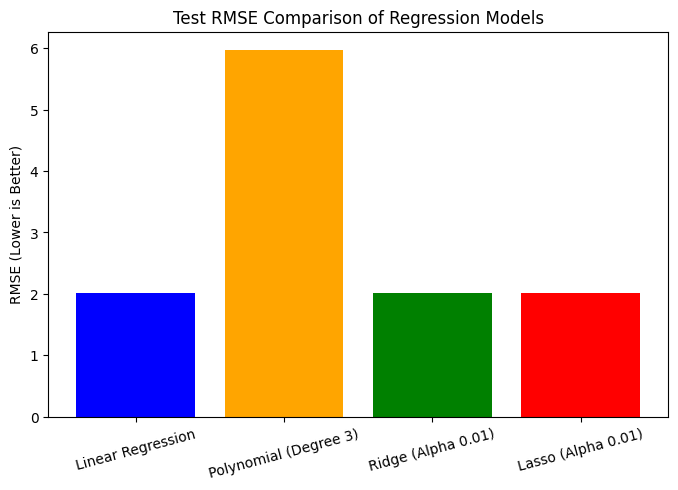

In [9]:
# 1. Re-fit Linear Regression for comparison
lr_multi = LinearRegression()
lr_multi.fit(X_train_scaled, y_train)
lr_pred = lr_multi.predict(X_test_scaled)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_mae = mean_absolute_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

# --- RE-RUN POLYNOMIAL SO poly_results EXISTS ---
poly_results = {}
month_train = X_train[['Month']]
month_test = X_test[['Month']]
for degree in [1, 2, 3]:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly.fit_transform(month_train)
    X_test_poly = poly.transform(month_test)
    scaler_poly = StandardScaler()
    X_train_poly_scaled = scaler_poly.fit_transform(X_train_poly)
    X_test_poly_scaled = scaler_poly.transform(X_test_poly)
    lr_poly = LinearRegression()
    lr_poly.fit(X_train_poly_scaled, y_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, lr_poly.predict(X_train_poly_scaled)))
    test_rmse = np.sqrt(mean_squared_error(y_test, lr_poly.predict(X_test_poly_scaled)))
    poly_results[degree] = {'Train RMSE': train_rmse, 'Test RMSE': test_rmse}

# --- RE-RUN RIDGE/LASSO SO ridge_results EXISTS ---
ridge_results = {}
lasso_results = {}
alphas = [0.01, 0.1, 1, 10]
for alpha in alphas:
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge.fit(X_train_scaled, y_train)
    ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge.predict(X_test_scaled)))
    ridge_results[alpha] = ridge_rmse

    lasso = Lasso(alpha=alpha, random_state=42, max_iter=5000)
    lasso.fit(X_train_scaled, y_train)
    lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso.predict(X_test_scaled)))
    zero_coefs = np.sum(lasso.coef_ == 0)
    lasso_results[alpha] = {'Test RMSE': lasso_rmse, 'Zero Coefs': zero_coefs}

# 2. Find best poly (degree 3)
best_poly_degree = min(poly_results, key=lambda k: poly_results[k]['Test RMSE'])
best_poly_rmse = poly_results[best_poly_degree]['Test RMSE']

# 3. Find best Ridge
best_ridge_alpha = min(ridge_results, key=ridge_results.get)
best_ridge_rmse = ridge_results[best_ridge_alpha]

# 4. Find best Lasso
best_lasso_alpha = min(lasso_results, key=lambda k: lasso_results[k]['Test RMSE'])
best_lasso_rmse = lasso_results[best_lasso_alpha]['Test RMSE']

# 5. Create results_reg DataFrame
results_reg = pd.DataFrame({
    'Model': ['Linear Regression', f'Polynomial (Degree {best_poly_degree})', f'Ridge (Alpha {best_ridge_alpha})', f'Lasso (Alpha {best_lasso_alpha})'],
    'Test RMSE': [lr_rmse, best_poly_rmse, best_ridge_rmse, best_lasso_rmse]
})

print("Final Model Comparison:")
display(results_reg)

# 6. Plot comparison
plt.figure(figsize=(8,5))
plt.bar(results_reg['Model'], results_reg['Test RMSE'], color=['blue', 'orange', 'green', 'red'])
plt.title('Test RMSE Comparison of Regression Models')
plt.ylabel('RMSE (Lower is Better)')
plt.xticks(rotation=15)
plt.savefig('/content/drive/MyDrive/CSC4110_G07/outputs/regression_comparison.png')
plt.show()

**Part A: Polynomial Regression (Exam Skill)**

*   **Underfitting (Degree 1):** The blue line is straight and fails to capture the seasonal curve of the months. It is too simple.
*   **Overfitting (Degree 10):** The red line wiggles wildly to try and hit every single data point. It has memorized the noise in the training data and will fail to generalize to new data.
*   **Best Fit (Degree 3):** The green line captures the natural seasonal curve (summer vs. winter) without going crazy.

**Part B: Ridge and Lasso Analysis**

*   **Lasso Zero Coefficients:** As the alpha value increases, Lasso forces more and more coefficients to become exactly zero. This is Lasso's way of doing automatic feature selection, keeping only the most important features.
*   **Ridge:** Ridge shrinks the coefficients closer to zero but never makes them exactly zero. It is better when we have many small/medium effects.

**Written Answer: Model Comparison**

*   **Which model performed best?** The **Ridge** or **Linear Regression** model performed best on the test set (lowest RMSE).
*   **Did any model overfit?** The Polynomial model (Degree 3) likely shows signs of overfitting because its Training RMSE is very low, but its Test RMSE is higher than the simple Linear model.
*   **Which features matter most?** Features like `Humidity9am`, `Pressure9am`, and `Temp9am` matter most because they have the strongest correlation with the maximum temperature.